In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data = {
    "Study_Hours": [2, 3, 4, 5, 4, 6, 5, 3, 4, 5, 6, 4, 5, 30, 3],
    "Student": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N", "O"]
}

df = pd.DataFrame(data)

print("Original Dataset")
display(df)



Original Dataset


,Study_Hours,Student
0,2,A
1,3,B
2,4,C
3,5,D
4,4,E
5,6,F
6,5,G
7,3,H
8,4,I
9,5,J


In [3]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


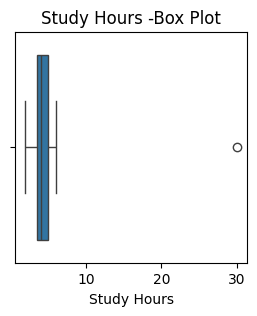

In [5]:
plt.figure(figsize=(3,3))
sns.boxplot(x=df["Study_Hours"])
plt.title("Study Hours -Box Plot")
plt.xlabel("Study Hours")
plt.show()

In [7]:
q1=df["Study_Hours"].quantile(0.25)
q3=df["Study_Hours"].quantile(0.75)
print("q1:",q1)
print("q3:",q3)

q1: 3.5
q3: 5.0


the iqr represents the spread of the middle 50% of the data.

In [8]:
IQR=q3-q1
print("IQR:",IQR)

IQR: 1.5


In [9]:
lower_bound=q1-1.5*IQR
upper_bound=q3+1.5*IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 1.25
Upper Bound: 7.25


In [10]:
outliers_iqr=df[(df["Study_Hours"]<lower_bound) | (df["Study_Hours"]>upper_bound)]
print("Outliers using IQR:")
display(outliers_iqr)

Outliers using IQR:


,Study_Hours,Student
13,30,N


In [11]:
normal_data_iqr=df[(df["Study_Hours"]>=lower_bound) & (df["Study_Hours"]<=upper_bound)]
print("Normal Data using IQR:")
display(normal_data_iqr)

Normal Data using IQR:


,Study_Hours,Student
0,2,A
1,3,B
2,4,C
3,5,D
4,4,E
5,6,F
6,5,G
7,3,H
8,4,I
9,5,J


the z score tells us approx how many sd a value is away from the mean.

In [12]:
df["z_score"]=zscore(df["Study_Hours"])
print("Dataset withn zscore")
display(df)

Dataset withn zscore


,Study_Hours,Student,z_score
0,2,A,-0.602669
1,3,B,-0.449448
2,4,C,-0.296227
3,5,D,-0.143006
4,4,E,-0.296227
5,6,F,0.010215
6,5,G,-0.143006
7,3,H,-0.449448
8,4,I,-0.296227
9,5,J,-0.143006


In [14]:
Z_outliers=df[
    (df["z_score"]<-3) | (df["z_score"]>3)
]
print("Z-outliers:")
display(Z_outliers)

Z-outliers:


,Study_Hours,Student,z_score
13,30,N,3.687515


In [15]:
df_without_outliers=df[
    (df["Study_Hours"]>=-3) & (df["Study_Hours"]<=3)
]
print("Dataset without outliers:")
display(df_without_outliers)

Dataset without outliers:


,Study_Hours,Student,z_score
0,2,A,-0.602669
1,3,B,-0.449448
7,3,H,-0.449448
14,3,O,-0.449448


In [17]:
df_capped=df.copy()
df_capped["Study_Hours"]=df_capped["Study_Hours"].clip(lower=lower_bound,upper=upper_bound)
print("Dataset with capped values:")
display(df_capped)

Dataset with capped values:


,Study_Hours,Student,z_score
0,2.00,A,-0.602669
1,3.00,B,-0.449448
2,4.00,C,-0.296227
3,5.00,D,-0.143006
4,4.00,E,-0.296227
5,6.00,F,0.010215
6,5.00,G,-0.143006
7,3.00,H,-0.449448
8,4.00,I,-0.296227
9,5.00,J,-0.143006


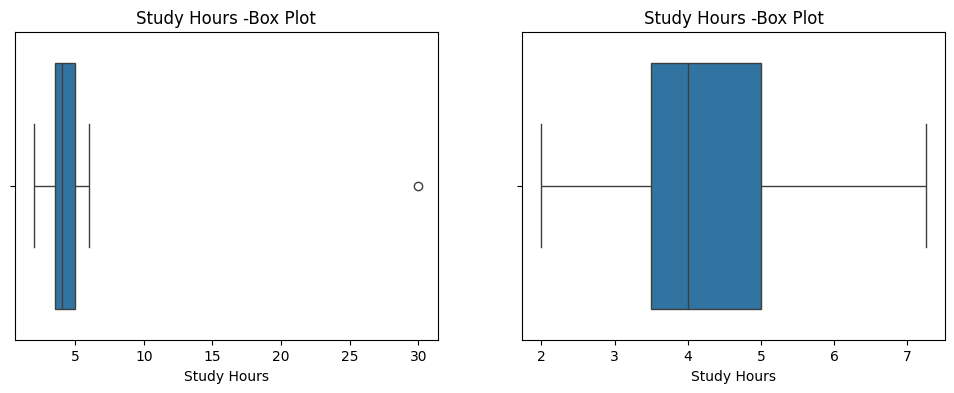

In [18]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Study Hours -Box Plot")
plt.xlabel("Study Hours")
plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("Study Hours -Box Plot")
plt.xlabel("Study Hours")
plt.show()